In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Data load

In [2]:
data = pd.read_csv("placement.csv")

In [3]:
data.shape

(100, 4)

In [4]:
data.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [5]:
data.isnull().sum()

Unnamed: 0    0
cgpa          0
iq            0
placement     0
dtype: int64

In [6]:
data = data.drop(columns='Unnamed: 0')

In [7]:
data.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       100 non-null    float64
 1   iq         100 non-null    float64
 2   placement  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


In [9]:
data.describe()

,cgpa,iq,placement
count,100.000000,100.000000,100.000000
mean,5.991000,123.580000,0.500000
std,1.143634,39.944198,0.502519
min,3.300000,37.000000,0.000000
25%,5.075000,101.500000,0.000000
50%,6.000000,127.500000,0.500000
75%,6.900000,149.000000,1.000000
max,8.500000,233.000000,1.000000


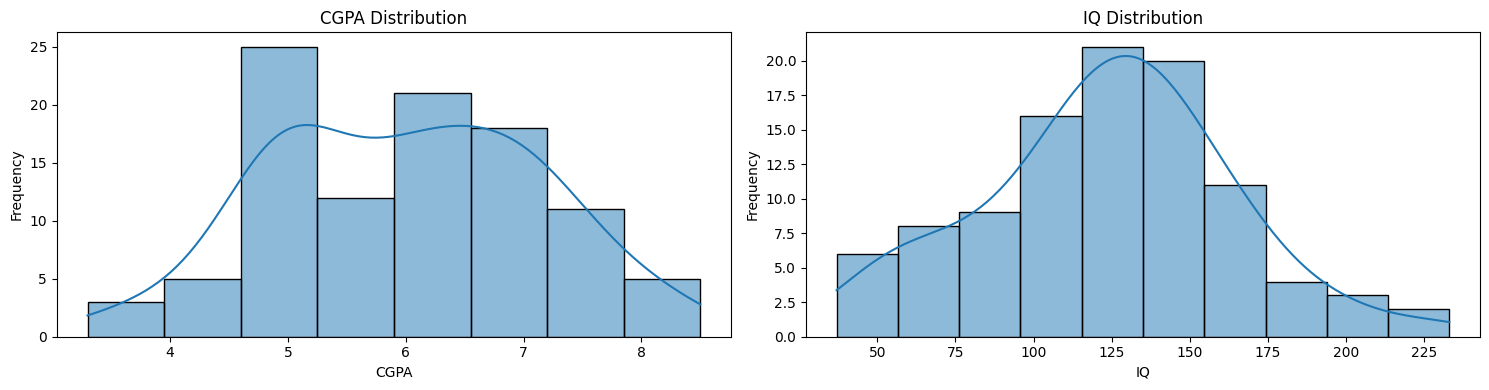

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))

# CGPA Distribution
sns.histplot(data=data, x='cgpa', kde=True, ax=ax[0])
ax[0].set_title('CGPA Distribution')
ax[0].set_xlabel('CGPA')
ax[0].set_ylabel('Frequency')

# IQ Distribution
sns.histplot(data=data, x='iq', kde=True, ax=ax[1])
ax[1].set_title('IQ Distribution')
ax[1].set_xlabel('IQ')
ax[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [11]:
placement_cate = data['placement'].replace({
    1:"Yes",
    0:"No"
})

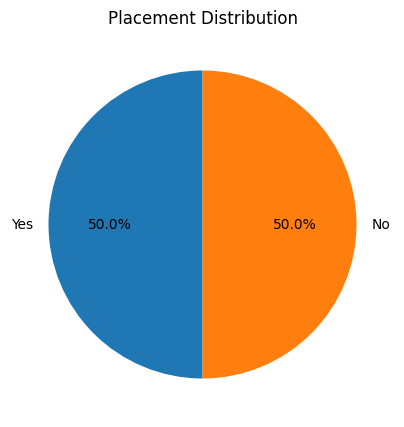

In [12]:
fig, ax = plt.subplots(figsize=(5, 5))

ax.pie(
    placement_cate.value_counts(),
    labels=placement_cate.value_counts().index,
    autopct='%1.1f%%',
    startangle=90
)

ax.set_title('Placement Distribution')

plt.show()

<Axes: xlabel='cgpa', ylabel='iq'>

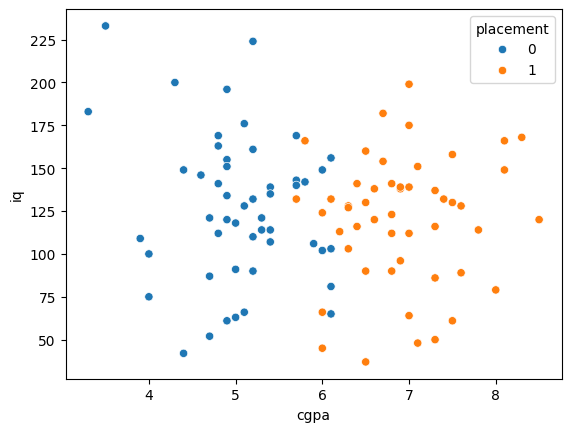

In [19]:
sns.scatterplot(x=data['cgpa'],y=data['iq'],hue=data['placement'])

In [20]:
from sklearn.linear_model import LogisticRegression 

In [21]:
model = LogisticRegression()
model

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [22]:
model.fit(data[['cgpa','iq']],data['placement'])

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [24]:
model.predict([[6.8,123]])

D:\learning\100-days scikit learn\venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])

In [26]:
model.score(data[['cgpa','iq']],data['placement'])

0.93

In [28]:
y_predict = model.predict(data[['cgpa','iq']])

In [58]:
from sklearn.metrics import confusion_matrix , classification_report

In [30]:
confusion_matrix_array = confusion_matrix(data['placement'],y_predict)
confusion_matrix_array

array([[45,  5],
       [ 2, 48]])

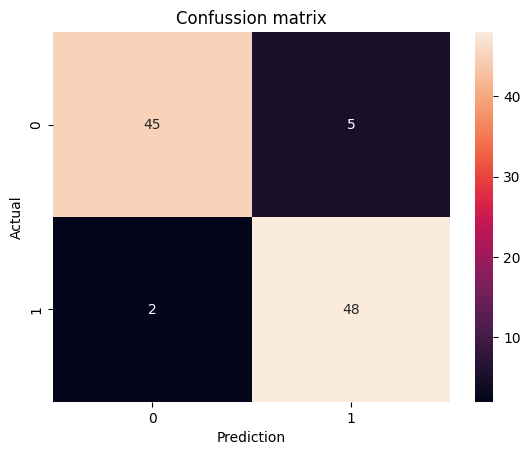

In [35]:
plt.title("Confussion matrix")
sns.heatmap(confusion_matrix_array,annot=True)
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.show()

### Accuracy

In [48]:
accuracy = (confusion_matrix_array[0][0]+confusion_matrix_array[1][1]) / np.sum(confusion_matrix_array)
accuracy

np.float64(0.93)

### Precision

In [50]:
precision = confusion_matrix_array[1][1] / np.sum([confusion_matrix_array[1][1],confusion_matrix_array[1][0]])
precision

np.float64(0.96)

### Recall

In [51]:
recall = confusion_matrix_array[1][1] / np.sum([confusion_matrix_array[1][1],confusion_matrix_array[0][1]])
recall

np.float64(0.9056603773584906)

### F1-score

In [53]:
f1_score = (2*(precision*recall)) / (precision + recall)
f1_score

np.float64(0.9320388349514563)

### Specificity

In [54]:
specificity = confusion_matrix_array[0][0] / np.sum([confusion_matrix_array[0][0],confusion_matrix_array[0][1]])
specificity

np.float64(0.9)

### Type-1

In [56]:
type_1 = confusion_matrix_array[0][0] / np.sum([confusion_matrix_array[0][0],confusion_matrix_array[0][1]])
type_1

np.float64(0.9)

### Type-2

In [57]:
type_2 = confusion_matrix_array[1][0] / np.sum([confusion_matrix_array[1][1],confusion_matrix_array[1][0]])
type_2

np.float64(0.04)

### Classification report

In [60]:
print(classification_report(data['placement'],y_predict))

              precision    recall  f1-score   support

           0       0.96      0.90      0.93        50
           1       0.91      0.96      0.93        50

    accuracy                           0.93       100
   macro avg       0.93      0.93      0.93       100
weighted avg       0.93      0.93      0.93       100



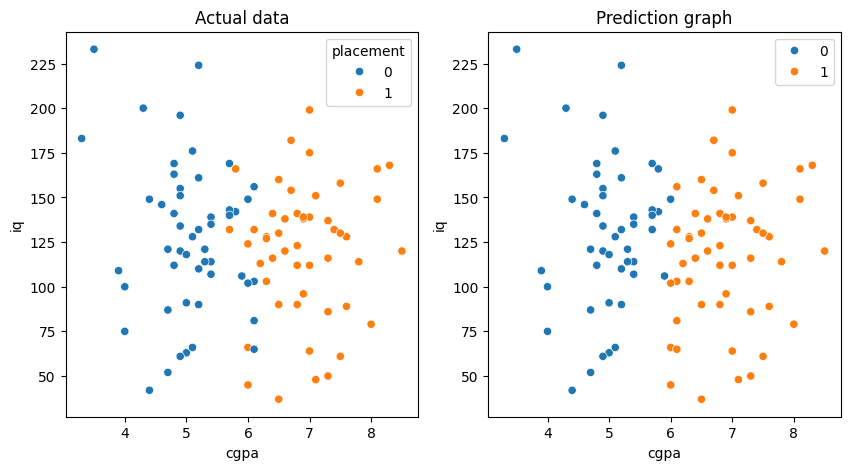

In [64]:
fig , ax = plt.subplots(1,2,figsize=(10,5))

ax[0].set_title("Actual data")
sns.scatterplot(data,x='cgpa',y='iq',hue='placement',ax=ax[0])

ax[1].set_title("Prediction graph")
sns.scatterplot(x=data['cgpa'],y=data['iq'],hue=y_predict,ax=ax[1])

plt.show()